In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score


In [2]:
waves = pd.read_csv('../Data/waves_2023.txt', sep=r'\s+')

In [3]:
waves.describe()

,YY,MM,DD,hh,mm,WDIR,WSPD,GST,WVHT,DPD,APD,MWD,PRES,ATMP,WTMP,DEWP,VIS,TIDE
count,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.0,17285.0,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.0,17285.0,17285.000000,17285.0,17285.0,17285.0
mean,2023.0,6.526063,15.800579,11.499277,40.985594,999.0,99.0,99.0,1.083535,12.161879,6.813054,234.556205,9999.0,999.0,17.196535,999.0,99.0,99.0
std,0.0,3.467253,8.817920,6.925343,15.007646,0.0,0.0,0.0,2.296129,4.165737,2.803208,49.429981,0.0,0.0,2.564664,0.0,0.0,0.0
min,2023.0,1.000000,1.000000,0.000000,0.000000,999.0,99.0,99.0,0.330000,2.860000,3.420000,10.000000,9999.0,999.0,11.800000,999.0,99.0,99.0
25%,2023.0,4.000000,8.000000,5.000000,26.000000,999.0,99.0,99.0,0.730000,9.090000,5.500000,179.000000,9999.0,999.0,14.600000,999.0,99.0,99.0
50%,2023.0,6.000000,16.000000,11.000000,26.000000,999.0,99.0,99.0,0.880000,12.500000,6.360000,263.000000,9999.0,999.0,17.500000,999.0,99.0,99.0
75%,2023.0,10.000000,23.000000,18.000000,56.000000,999.0,99.0,99.0,1.140000,14.290000,7.550000,271.000000,9999.0,999.0,19.400000,999.0,99.0,99.0
max,2023.0,12.000000,31.000000,23.000000,56.000000,999.0,99.0,99.0,99.000000,99.000000,99.000000,999.000000,9999.0,999.0,23.900000,999.0,99.0,99.0


In [4]:
waves= waves.drop(['WDIR','WSPD','GST','PRES','ATMP','DEWP','VIS','TIDE'], axis=1)
waves.describe()

,YY,MM,DD,hh,mm,WVHT,DPD,APD,MWD,WTMP
count,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000
mean,2023.0,6.526063,15.800579,11.499277,40.985594,1.083535,12.161879,6.813054,234.556205,17.196535
std,0.0,3.467253,8.817920,6.925343,15.007646,2.296129,4.165737,2.803208,49.429981,2.564664
min,2023.0,1.000000,1.000000,0.000000,0.000000,0.330000,2.860000,3.420000,10.000000,11.800000
25%,2023.0,4.000000,8.000000,5.000000,26.000000,0.730000,9.090000,5.500000,179.000000,14.600000
50%,2023.0,6.000000,16.000000,11.000000,26.000000,0.880000,12.500000,6.360000,263.000000,17.500000
75%,2023.0,10.000000,23.000000,18.000000,56.000000,1.140000,14.290000,7.550000,271.000000,19.400000
max,2023.0,12.000000,31.000000,23.000000,56.000000,99.000000,99.000000,99.000000,999.000000,23.900000


In [5]:
# WVHT = Wave Height (m)
# DPD = Dominant wave period (seconds)
# APD = Average wave period (seconds)
# MWD = The direction from which the waves at the dominant period (DPD) are coming
# WTMP = Sea surface temperature (Celsius)

waves = waves[waves['WVHT'] < 99]
waves = waves[waves['DPD'] < 99]
waves = waves[waves['APD'] < 99]
waves = waves[waves['MWD'] < 999]

In [6]:
wavesML = waves.drop(['YY','MM','DD','hh','mm'], axis = 1)
wavesML.describe()

,WVHT,DPD,APD,MWD,WTMP
count,17276.000000,17276.000000,17276.000000,17276.000000,17276.000000
mean,1.032525,12.116640,6.765029,234.157965,17.195294
std,0.526637,3.664928,1.852623,46.260000,2.564729
min,0.330000,2.860000,3.420000,10.000000,11.800000
25%,0.730000,9.090000,5.500000,179.000000,14.600000
50%,0.880000,12.500000,6.360000,263.000000,17.500000
75%,1.140000,14.290000,7.550000,271.000000,19.400000
max,5.130000,25.000000,15.790000,306.000000,23.900000


In [7]:
df_X = wavesML.drop(['WVHT'], axis=1).to_numpy().copy()
df_y = wavesML['WVHT'].to_numpy().copy()

X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size=0.10, random_state=38)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.10, random_state=38)

In [8]:
# Baseline: Linear Regression

regL = LinearRegression()
regL.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[-0.02, 0.12, 0. ,-0.04]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.7321
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](4,)","[5471.35, 413.97, 274.6 , 170.85]"


In [9]:
# Decision Tree Regressor

# max_depth=5 prevents it from growing infinitely and overfitting completely

regDT = DecisionTreeRegressor(max_depth=5, random_state=38)
regDT.fit(X_train, y_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",38
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max

In [10]:
# Random Forest Regressor

regRF = RandomForestRegressor(n_estimators=25, random_state=38, n_jobs=-1)
regRF = regRF.fit(X_train, y_train)


In [11]:
# Combine train, validation and test

models = {
    "Linear Regression (regL)": regL,
    "Decision Tree (regDT)": regDT,
    "Random Forest (regRF)": regRF
}


print(f"{'Model Variable Name':<30} | {'Dataset':<12} | {'RMSE':<12} | {'R\u00b2':<12}")
print("-" * 70)

for name, model in models.items():
    
    for dataset, X_data, y_data in [("Train", X_train, y_train), 
                                       ("Val", X_val, y_val), 
                                       ("Test", X_test, y_test)]:
        
        preds = model.predict(X_data)
        rmse = np.sqrt(mean_squared_error(y_data, preds))
        r2 = r2_score(y_data, preds)
        
        print(f"{name:<30} | {dataset:<12} | {rmse:<12.4f} | {r2:<12.4f}")
    print("-" * 70)


Model Variable Name            | Dataset      | RMSE         | R²          
----------------------------------------------------------------------
Linear Regression (regL)       | Train        | 0.4444       | 0.2910      
Linear Regression (regL)       | Val          | 0.4368       | 0.3305      
Linear Regression (regL)       | Test         | 0.4304       | 0.2886      
----------------------------------------------------------------------
Decision Tree (regDT)          | Train        | 0.3578       | 0.5404      
Decision Tree (regDT)          | Val          | 0.3639       | 0.5352      
Decision Tree (regDT)          | Test         | 0.3610       | 0.4993      
----------------------------------------------------------------------
Random Forest (regRF)          | Train        | 0.1117       | 0.9552      
Random Forest (regRF)          | Val          | 0.2800       | 0.7248      
Random Forest (regRF)          | Test         | 0.2795       | 0.6999      
---------------------------

### In these 3, Random Forest Regressor works best with lowest error and highest R2

### Cost Function
Linear Regressor: Mean Squared Error (Ordinary Least Squares)

Dicision Tree Regressor: Mean Squared Error

Random Forest Regressor: Mean Squared Error



## Hyperparameters: Using n_estimators


In [12]:
n_trees_list = [1, 5, 10, 25, 50, 100, 200, 500, 1000]
val_r2 = [] 

for n in n_trees_list:
    model = RandomForestRegressor(n_estimators=n, random_state=38, n_jobs=-1)
    model.fit(X_train, y_train)
    val_r2.append(model.score(X_val, y_val)) 
    

best_tree_index = int(np.argmax(val_r2))
best_n = n_trees_list[best_tree_index]
print('Best number of trees based on R²:', best_n)

rf_best = RandomForestRegressor(n_estimators=best_n, random_state=38, n_jobs=-1)
rf_best.fit(X_train, y_train) 

print(f'Test R² Score: {regRF.score(X_test, y_test):.3f} (25 trees) vs {rf_best.score(X_test, y_test):.3f} ({best_n} trees)')


Best number of trees based on R²: 100
Test R² Score: 0.700 (25 trees) vs 0.708 (100 trees)


## Redoing train/validation splits

In [13]:
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.20, random_state=38)

In [14]:
# Baseline: Linear Regression

regL = LinearRegression()
regL.fit(X_train, y_train)


# Decision Tree Regressor

regDT = DecisionTreeRegressor(max_depth=5, random_state=38)
regDT.fit(X_train, y_train)


# Random Forest Regressor

regRF = RandomForestRegressor(n_estimators=25, random_state=38, n_jobs=-1)
regRF = regRF.fit(X_train, y_train)

In [15]:
# Combine train, validation and test

models = {
    "Linear Regression (regL)": regL,
    "Decision Tree (regDT)": regDT,
    "Random Forest (regRF)": regRF
}


print(f"{'Model Variable Name':<30} | {'Dataset':<12} | {'RMSE':<12} | {'R\u00b2':<12}")
print("-" * 70)

for name, model in models.items():
    
    for dataset, X_data, y_data in [("Train", X_train, y_train), 
                                       ("Val", X_val, y_val), 
                                       ("Test", X_test, y_test)]:
        
        preds = model.predict(X_data)
        rmse = np.sqrt(mean_squared_error(y_data, preds))
        r2 = r2_score(y_data, preds)
        
        print(f"{name:<30} | {dataset:<12} | {rmse:<12.4f} | {r2:<12.4f}")
    print("-" * 70)

Model Variable Name            | Dataset      | RMSE         | R²          
----------------------------------------------------------------------
Linear Regression (regL)       | Train        | 0.4438       | 0.2866      
Linear Regression (regL)       | Val          | 0.4469       | 0.3072      
Linear Regression (regL)       | Test         | 0.4303       | 0.2889      
----------------------------------------------------------------------
Decision Tree (regDT)          | Train        | 0.3581       | 0.5356      
Decision Tree (regDT)          | Val          | 0.3618       | 0.5459      
Decision Tree (regDT)          | Test         | 0.3596       | 0.5033      
----------------------------------------------------------------------
Random Forest (regRF)          | Train        | 0.1146       | 0.9525      
Random Forest (regRF)          | Val          | 0.3027       | 0.6821      
Random Forest (regRF)          | Test         | 0.2908       | 0.6752      
---------------------------

### I changed train/validation splits from 90/10 to 80/20, I didn't get the same answers. They are slightly different.

In [16]:
tree_counts = [2, 10, 25, 50, 100, 250, 500, 1000]
train_errors = []
val_errors = []


print(f"{'Trees':<6} | {'Train RMSE':<10} | {'Val RMSE':<10} | {'RMSE Gap (Val - Train)':<22}")
print("-" * 58)

for n in tree_counts:
    rf_model = RandomForestRegressor(n_estimators=n, random_state=38, n_jobs=-1)
    rf_model.fit(X_train, y_train)
    
    # Calculate Training Error (RMSE)
    train_pred = rf_model.predict(X_train)
    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    train_errors.append(train_rmse)
    
    # Calculate Validation Error (RMSE)
    val_pred = rf_model.predict(X_val)
    val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))
    val_errors.append(val_rmse)
    
    # Calculate the exact difference (The Overfitting Gap)
    rmse_diff = val_rmse - train_rmse
    
    print(f"{n:<6} | {train_rmse:<10.4f} | {val_rmse:<10.4f} | {rmse_diff:<22.4f}")


Trees  | Train RMSE | Val RMSE   | RMSE Gap (Val - Train)
----------------------------------------------------------
2      | 0.1866     | 0.3727     | 0.1861                
10     | 0.1237     | 0.3146     | 0.1908                
25     | 0.1146     | 0.3027     | 0.1882                
50     | 0.1104     | 0.3006     | 0.1901                
100    | 0.1081     | 0.2979     | 0.1898                
250    | 0.1061     | 0.2980     | 0.1919                
500    | 0.1056     | 0.2981     | 0.1925                
1000   | 0.1049     | 0.2974     | 0.1925                


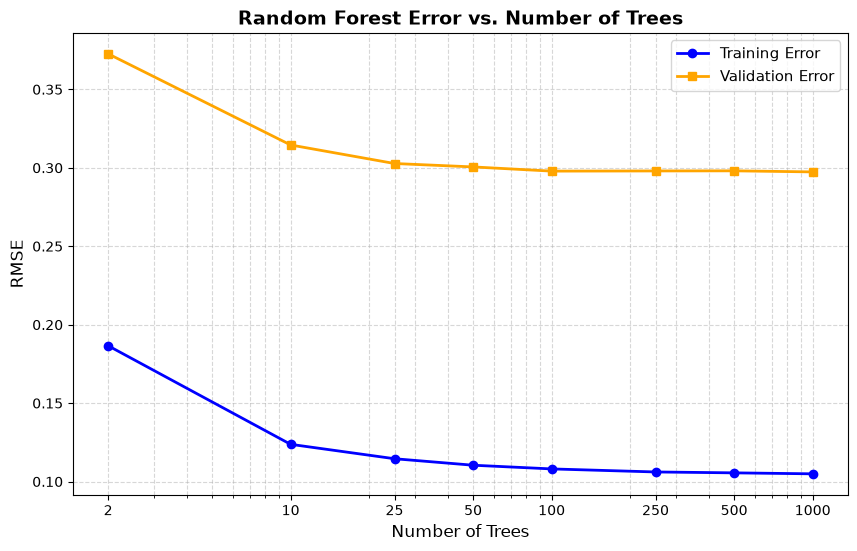

In [17]:
plt.figure(figsize=(10, 6))
plt.plot(tree_counts, train_errors, marker='o', label='Training Error', color='blue', linewidth=2)
plt.plot(tree_counts, val_errors, marker='s', label='Validation Error', color='orange', linewidth=2)

plt.title('Random Forest Error vs. Number of Trees', fontsize=14, fontweight='bold')
plt.xlabel('Number of Trees', fontsize=12)
plt.ylabel('RMSE', fontsize=12)
plt.xscale('log')  # Log scale spreads out 2, 10, 25 visually from 1,000
plt.xticks(tree_counts, labels=[str(t) for t in tree_counts])
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend(fontsize=11)
plt.show()

I do see the RMSE gap between tarining and validation dataset getting bigger as the number of trees getting higher after 25 tress. It's a sign of overfitting. Still, the difference between 100 and 1000 trees in validation RMSE is not that much higher, so the model with 100 trees is as good as 1000 trees with being efficient in time and disk space.